In [1]:
%pip install numpy pandas matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [3]:

import numpy as np
import pandas as pd

# Generate random student data
np.random.seed(42)

n = 600

# Student details
cgpa = np.random.uniform(5, 10, n)

aptitude = np.random.randint(30, 101, n)

technical = np.random.randint(30, 101, n)

communication = np.random.randint(30, 101, n)

internships = np.random.randint(0, 4, n)

# Calculate placement probability
score = (
    -3.5
    + 0.9 * (cgpa - 5)
    + 0.018 * (aptitude - 50)
    + 0.018 * (technical - 50)
    + 0.012 * (communication - 50)
    + 0.45 * internships
)

probability = 1 / (1 + np.exp(-score))

# Generate placement status
placement = np.random.binomial(1, probability)

# Create dataset
data = pd.DataFrame({
    'CGPA': cgpa,
    'Aptitude_Score': aptitude,
    'Technical_Score': technical,
    'Communication_Score': communication,
    'Internships': internships,
    'Placement_Status': placement
})

# Save dataset
data.to_csv("placement_data.csv", index=False)

print("Dataset created successfully!")


Dataset created successfully!


In [4]:

print(data.head(10))


       CGPA  Aptitude_Score  Technical_Score  Communication_Score  \
0  6.872701              34               34                   52   
1  9.753572              71               77                   55   
2  8.659970              90               47                   97   
3  7.993292              51               99                   84   
4  5.780093              50               66                   35   
5  5.779973              99               89                   64   
6  5.290418              30               77                   51   
7  9.330881              34               57                   72   
8  8.005575              41               98                   44   
9  8.540363              75               69                   89   

   Internships  Placement_Status  
0            2                 0  
1            2                 1  
2            2                 1  
3            2                 1  
4            2                 0  
5            1                

In [5]:

print("Dataset Shape:", data.shape)

print("\nDataset Information:")
print(data.info())

print("\nPlacement Status:")
print(data['Placement_Status'].value_counts())


Dataset Shape: (600, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CGPA                 600 non-null    float64
 1   Aptitude_Score       600 non-null    int32  
 2   Technical_Score      600 non-null    int32  
 3   Communication_Score  600 non-null    int32  
 4   Internships          600 non-null    int32  
 5   Placement_Status     600 non-null    int32  
dtypes: float64(1), int32(5)
memory usage: 16.5 KB
None

Placement Status:
Placement_Status
1    326
0    274
Name: count, dtype: int64


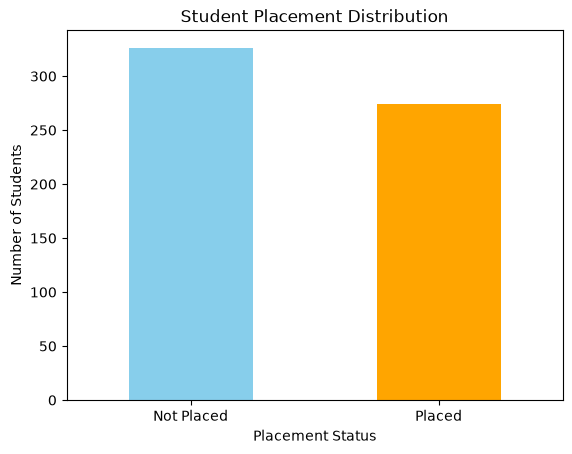

In [6]:

import matplotlib.pyplot as plt

data['Placement_Status'].value_counts().plot(
    kind='bar',
    color=['skyblue', 'orange']
)

plt.title("Student Placement Distribution")

plt.xlabel("Placement Status")

plt.ylabel("Number of Students")

plt.xticks([0, 1], ['Not Placed', 'Placed'], rotation=0)

plt.show()


In [7]:
import pandas as pd

data = pd.read_csv("placement_data.csv")

print(data.head(10))
print(data.shape)

       CGPA  Aptitude_Score  Technical_Score  Communication_Score  \
0  6.872701              34               34                   52   
1  9.753572              71               77                   55   
2  8.659970              90               47                   97   
3  7.993292              51               99                   84   
4  5.780093              50               66                   35   
5  5.779973              99               89                   64   
6  5.290418              30               77                   51   
7  9.330881              34               57                   72   
8  8.005575              41               98                   44   
9  8.540363              75               69                   89   

   Internships  Placement_Status  
0            2                 0  
1            2                 1  
2            2                 1  
3            2                 1  
4            2                 0  
5            1                

In [8]:

import pandas as pd
import numpy as np

data = pd.read_csv("placement_data.csv")

print(data.head())


       CGPA  Aptitude_Score  Technical_Score  Communication_Score  \
0  6.872701              34               34                   52   
1  9.753572              71               77                   55   
2  8.659970              90               47                   97   
3  7.993292              51               99                   84   
4  5.780093              50               66                   35   

   Internships  Placement_Status  
0            2                 0  
1            2                 1  
2            2                 1  
3            2                 1  
4            2                 0  


In [9]:

print("Dataset Shape:", data.shape)

print("\nDataset Information:")
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())


Dataset Shape: (600, 6)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CGPA                 600 non-null    float64
 1   Aptitude_Score       600 non-null    int64  
 2   Technical_Score      600 non-null    int64  
 3   Communication_Score  600 non-null    int64  
 4   Internships          600 non-null    int64  
 5   Placement_Status     600 non-null    int64  
dtypes: float64(1), int64(5)
memory usage: 28.3 KB
None

Missing Values:
CGPA                   0
Aptitude_Score         0
Technical_Score        0
Communication_Score    0
Internships            0
Placement_Status       0
dtype: int64


In [10]:

X = data.drop("Placement_Status", axis=1)

y = data["Placement_Status"]

print("Input Variables:")
print(X.head())

print("\nOutput Variable:")
print(y.head())


Input Variables:
       CGPA  Aptitude_Score  Technical_Score  Communication_Score  Internships
0  6.872701              34               34                   52            2
1  9.753572              71               77                   55            2
2  8.659970              90               47                   97            2
3  7.993292              51               99                   84            2
4  5.780093              50               66                   35            2

Output Variable:
0    0
1    1
2    1
3    1
4    0
Name: Placement_Status, dtype: int64


In [11]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)


Training Data: (480, 5)
Testing Data: (120, 5)


In [12]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")


Feature Scaling Completed!


In [13]:

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model Trained Successfully!")


Model Trained Successfully!


In [14]:

y_pred = model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])


Actual Values:
[0 0 1 1 1 1 0 1 1 1]

Predicted Values:
[0 0 1 1 1 0 0 1 0 1]


In [15]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 78.33333333333333 %


In [16]:

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))


Precision: 0.7910447761194029
Recall: 0.8153846153846154
F1 Score: 0.803030303030303


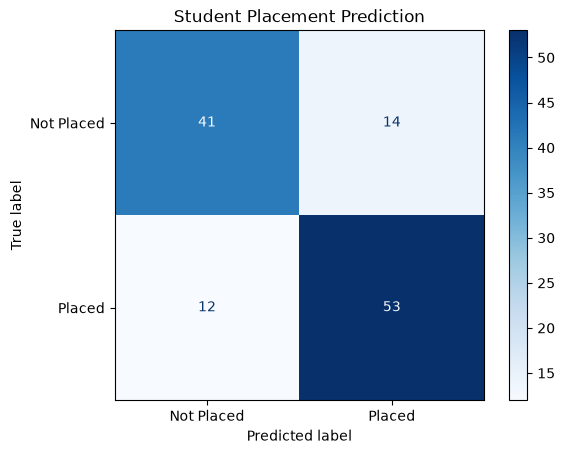

In [17]:

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Placed", "Placed"]
)

display.plot(cmap="Blues")

plt.title("Student Placement Prediction")

plt.show()


In [18]:
%gui tk

In [19]:
import tkinter as tk
from tkinter import messagebox

In [20]:
root = tk.Tk()

root.title("Student Placement Prediction System")

root.geometry("600x650")

root.configure(bg="#EAF2F8")

print("GUI Window Created")

GUI Window Created


In [21]:
title = tk.Label(
    root,
    text="STUDENT PLACEMENT PREDICTION",
    font=("Arial", 18, "bold"),
    bg="#EAF2F8",
    fg="#154360"
)

title.pack(pady=20)

In [22]:
fields = [
    "CGPA",
    "Aptitude Score",
    "Technical Score",
    "Communication Score",
    "Internships"
]

entries = []

for field in fields:

    label = tk.Label(
        root,
        text=field,
        font=("Arial", 12),
        bg="#EAF2F8"
    )

    label.pack(pady=5)

    entry = tk.Entry(
        root,
        font=("Arial", 12)
    )

    entry.pack(pady=5)

    entries.append(entry)

In [23]:
def predict():

    try:

        cgpa = float(entries[0].get())

        aptitude = float(entries[1].get())

        technical = float(entries[2].get())

        communication = float(entries[3].get())

        internships = int(entries[4].get())

        if not 0 <= cgpa <= 10:
            raise ValueError("CGPA must be between 0 and 10")

        if not all(0 <= x <= 100 for x in
                   [aptitude, technical, communication]):
            raise ValueError("Scores must be between 0 and 100")

        if not 0 <= internships <= 10:
            raise ValueError("Internships must be between 0 and 10")

        student = pd.DataFrame(
            [[cgpa, aptitude, technical,
              communication, internships]],
            columns=X.columns
        )

        student_scaled = scaler.transform(student)

        prediction = model.predict(student_scaled)

        probability = model.predict_proba(student_scaled)[0][1]

        if prediction[0] == 1:

            result = "Higher Placement Likelihood"

        else:

            result = "Lower Placement Likelihood"

        output.config(
            text=result +
            "\nEstimated Probability: " +
            str(round(probability * 100, 2)) + "%"
        )

    except ValueError as e:

        messagebox.showerror("Input Error", str(e))

In [24]:
button = tk.Button(
    root,
    text="PREDICT PLACEMENT",
    command=predict,
    font=("Arial", 13, "bold"),
    bg="#2874A6",
    fg="white"
)

button.pack(pady=25)

In [25]:
output = tk.Label(
    root,
    text="Prediction will appear here",
    font=("Arial", 14, "bold"),
    bg="#EAF2F8",
    fg="#154360"
)

output.pack(pady=20)

In [26]:
accuracy_label = tk.Label(
    root,
    text="Model Accuracy: " +
    str(round(accuracy * 100, 2)) + "%",
    font=("Arial", 12, "bold"),
    bg="#EAF2F8"
)

accuracy_label.pack(pady=10)

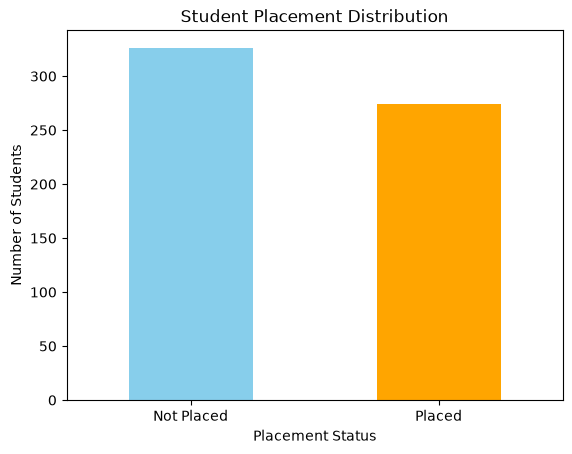

In [27]:
import matplotlib.pyplot as plt

data['Placement_Status'].value_counts().plot(
    kind='bar',
    color=['skyblue', 'orange']
)

plt.title("Student Placement Distribution")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.xticks([0, 1], ["Not Placed", "Placed"], rotation=0)

plt.show()

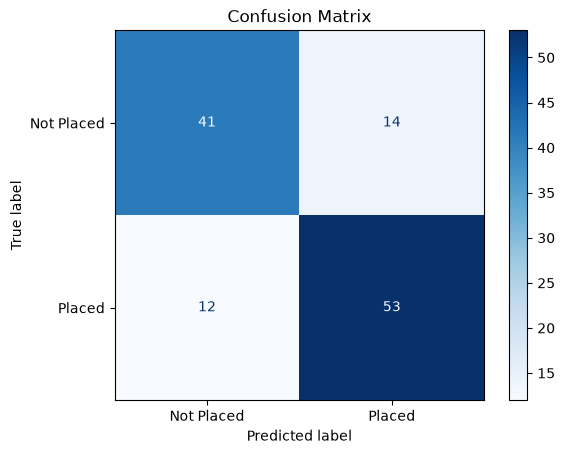

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Placed", "Placed"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [29]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(comparison.head(15))

    Actual  Predicted
0        0          0
1        0          0
2        1          1
3        1          1
4        1          1
5        1          0
6        0          0
7        1          1
8        1          0
9        1          1
10       0          0
11       0          0
12       0          0
13       0          0
14       0          1


In [30]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [31]:
import joblib

joblib.dump(model, "placement_model.pkl")

joblib.dump(scaler, "placement_scaler.pkl")

print("Model and Scaler Saved Successfully!")

Model and Scaler Saved Successfully!


In [32]:
loaded_model = joblib.load("placement_model.pkl")

loaded_scaler = joblib.load("placement_scaler.pkl")

print("Saved Model Loaded Successfully!")

Saved Model Loaded Successfully!


In [33]:
import joblib

model = joblib.load("placement_model.pkl")
scaler = joblib.load("placement_scaler.pkl")

print("Model and scaler loaded successfully!")

Model and scaler loaded successfully!


In [34]:
from sklearn.metrics import accuracy_score

X_test_scaled = scaler.transform(X_test)

y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 78.33 %


In [35]:
accuracy_label = tk.Label(
    root,
    text=f"Model Accuracy: {accuracy * 100:.2f}%",
    font=("Arial", 14, "bold"),
    bg="#EAF2F8",
    fg="#154360"
)

accuracy_label.pack(pady=15)